# Anomaly scores and observed Faith PD relative to the NJODE conditional mean around antibiotic exposures

For every observation of an exposed infant from 3 months before to 6 months after its 1st, 2nd and 3rd antibiotic (abx) exposure, the observed Faith PD $x_t$ is compared with the conditional mean $\mu_t$ that the NJODE forecasts for that infant and day (`only_jump_before_abx_exposure` = 1, 2, 3: after the exposure the model is no longer updated with microbial observations, so these are forecasts from the state before the exposure), and with the predicted conditional standard deviation times the horizon-dependent scaling factor, $\tilde\sigma_t$, which the anomaly score uses. Each figure shows, over continuous time since exposure and with a bootstrap over infants for the confidence bands:

1. the anomaly score $S = -\ln(p)$ of every observation, the quantity used throughout the manuscript, and its smoothed cohort trajectory;
2. the relative deficit $(x_t - \mu_t) / \mu_t$, the size of the deficit in biological units, with the model's expected range for an observation, $\pm 1.96\,\tilde\sigma_t / \mu_t$ averaged over the observations near each time point as the root of the mean individual variance, and each observation colored by its anomaly score;
3. for each time point, the number of observations contributing to the displayed value there (those within two bandwidths on the same side of the exposure, which hold 95% of the kernel weight) and the number of unique infants they come from.

All observations in the window enter the continuous-time figures, including every sample before the exposure. One composed box-plot figure shows the relative deficit per month after the 1st, 2nd and 3rd exposure, panel by panel in the style of the score box plots of `evaluate_scores.ipynb` (same selection, tests, colors and significance stars), which are not repeated here.

Unlike Fig. 4c of the manuscript, the reference is each infant's own model expectation rather than age-matched unexposed infants, and time is not binned by month.

Inputs are the `{split}_cond_moments_{n}_coord-0.csv` tables written next to the scores by

```
uv run python Microbial_AD_eval.py --forecast_model_ids=AD_microbial_novel_alpha_div_ids2_1 --ad_params=param_list_AD_microbial_novel_alpha_div2 --forecast_saved_models_path=AD_microbial_novel_alpha_div2 --compute_scores=True --save_cond_moments=True
```

The observation selection follows `evaluate_scores.ipynb`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import transforms
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.stats import norm

import seaborn as sns

from src.figure_style import legend_above_footnote
from src.utils_eval_score import (
    _add_md_from_ft,
    _add_month_bins,
    _get_abx_info,
    _get_ordinal_suffix,
    _create_subplot,
    _select_samples_around_nth_abx_exposure,
    perform_significance_tests,
)

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans"})
plt.style.use("tableau-colorblind10")
# embed fonts as TrueType (Type 42) so that PDF viewers render the text correctly
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
# avg. number of days per month
DAYS_PER_MONTH = 30.437

In [2]:
#### USER INPUT START

# model ID
ID = 57

# name of the model
model_name = f"saved_models_microbial_novel_alpha_div2/id-{ID}"
# which model version to evaluate: "best" or "last"
point_to_evaluate = "best"

# name of feature dataset used for model
ft_name = "ft_vat19_anomaly_v20240806_entero_genus"
# name of abx time-series used for model
abx_ts_name = "ts_vat19_abx_v20240806"

# limit evaluation to samples and abx exposures up to this many months of age
limit_months = 24.0

# how many months before and after the n-th abx exposure to consider
# (as in evaluate_scores.ipynb)
min_samples = -3.0
max_samples = 6.0

# scaling factor options (as in evaluate_scores.ipynb):
# non-centered = "nc_std" or centered = "std"
stddev_type = "nc_std"
# moving average window size: 30 or 10
moving_avg = 10
# whether to remove duplicates: "--RD-True" or ""
duplicates = "--RD-True"
# using lower bound of 1 for SFs: "lower_bound-1" or ""
lower_bound = ""

# smoothing: Gaussian kernel bandwidth in months and bootstrap over infants
bandwidth_months = 0.5
n_bootstrap = 1000
bootstrap_seed = 0
# observations within this many bandwidths of a time point count as contributing to
# its smoothed value (two bandwidths hold 95% of the Gaussian kernel's weight)
support_bandwidths = 2.0
# curves are only shown while at least this many infants contribute to the time point
# (counted outwards from the exposure)
min_infants = 10

# font size of the composed per-month box-plot figure (evaluate_scores.ipynb uses 10
# for its single figures; the composite is scaled down on the page)
boxplot_font_size = 14

#### USER INPUT END

In [3]:
base_path = f"../data/{model_name}/anomaly_detection/"
folder_name = (
    f"using-SF_{stddev_type}_z_scores--moving_avg-{moving_avg}-cummax{lower_bound}{duplicates}"
)
scores_path = f"{base_path}scores_{point_to_evaluate}_normal/{folder_name}/"
evaluation_path = (
    f"{base_path}evaluation_{point_to_evaluate}_cond_mean_{stddev_type}"
    f"_ma{moving_avg}{duplicates.replace('-', '_').lower()}/"
)
os.makedirs(evaluation_path, exist_ok=True)

## Load the conditional moments of all exposed infants

As in `evaluate_scores.ipynb`, exposed infants of the AD train and validation splits are pooled, since none of them were used to train the forecasting model, samples are limited to `limit_months` of age, and the sample metadata (cumulative abx count, diet, Faith PD) is merged from the feature table.

In [4]:
def load_cond_moments(scores_path, n):
    """Observed (infant, day) rows with the NJODE conditional moments, model
    updated with microbial observations only before the n-th abx exposure."""
    table = pd.concat(
        [
            pd.read_csv(f"{scores_path}{split}_cond_moments_{n}_coord-0.csv")
            for split in ["train", "val"]
        ],
        ignore_index=True,
    )
    table = table[table["abx"].astype(bool)].copy()
    table = _add_month_bins(table)
    table = table[table["month5_bin"] <= limit_months].copy()
    table = _add_md_from_ft(table, ft_name)
    table["rel_deficit"] = 100 * (table["obs"] - table["cond_mean"]) / table["cond_mean"]
    # predicted conditional std times the scaling factor, as used by the anomaly score
    table["std_scaled"] = table["cond_std"] * table["sf"]
    table["rel_std_pct"] = 100 * table["std_scaled"] / table["cond_mean"]
    table["z"] = (table["obs"] - table["cond_mean"]) / table["std_scaled"]
    return table


cond_moments = {n: load_cond_moments(scores_path, n) for n in [1, 2, 3]}
abx_df = _get_abx_info(f"../data/original_data/{abx_ts_name}.tsv", limit_months=limit_months)
cond_moments[1].head()

,host_id,abx,day,obs,cond_mean,cond_std,sf,abx_exposure,score,month_bin,...,diet_weaning,delivery_mode,div_alpha_faith_pd,div_alpha_observed_features,div_alpha_shannon,max_abx_w_microbiome,rel_deficit,std_scaled,rel_std_pct,z
0,T012977,True,683,38.031780,13.765209,6.470286,1.633565,1,0.010901,22,...,yes,vaginal,38.031782,116.532,5.372679,1.0,176.289158,10.569635,76.785140,2.295876
1,E008643,True,109,1.460855,12.109880,4.249396,1.281592,0,3.678191,4,...,no,vaginal,1.460855,2.000,0.764274,1.0,-87.936667,5.445991,44.971471,-1.955388
2,E008643,True,314,16.708935,8.245068,6.754608,1.370930,0,0.198883,10,...,yes,vaginal,16.708934,29.730,3.601156,1.0,102.653696,9.260093,112.310691,0.914015
3,E008643,True,495,8.429625,21.583660,6.767396,1.347174,0,2.596488,16,...,yes,vaginal,8.429625,11.210,0.929374,1.0,-60.944414,9.116861,42.239643,-1.442825
4,E008643,True,587,18.529000,13.463842,5.704791,1.257199,0,0.274465,19,...,yes,vaginal,18.528999,45.944,2.764697,1.0,37.620450,7.172060,53.269043,0.706235


In [5]:
# consistency checks: the tabulated observation is the Faith PD of the feature
# table, and mean, std and scaling factor reproduce the saved left-tail score
for n, table in cond_moments.items():
    np.testing.assert_allclose(table["obs"], table["div_alpha_faith_pd"], rtol=1e-6)
    z = (table["obs"] - table["cond_mean"]) / (table["cond_std"] * table["sf"])
    np.testing.assert_allclose(-np.log(norm.cdf(z) + 1e-10), table["score"], atol=1e-6)
print("conditional moments are consistent with the feature table and the saved scores")

conditional moments are consistent with the feature table and the saved scores


## Select observations around the n-th abx exposure

Membership follows `_select_samples_around_nth_abx_exposure` in `evaluate_scores.ipynb`: the half-month age bin of a sample lies in `[min_samples, max_samples)` months relative to the recorded start of the n-th exposure, and the cumulative exposure count of the sample is n-1 or n, so no later exposure has occurred. Samples in bins before the exposure are the pre-exposure trajectory, samples in bins at or after it the post-exposure trajectory. Differences to `evaluate_scores.ipynb`: time since exposure is kept continuous (exact sample age in months minus the recorded half-month exposure start), and all samples of an infant are kept, whereas the box plots keep the last sample per month and group the pre-exposure samples into the last one before the exposure.

In [6]:
def select_around_nth_abx_exposure(table, abx_df, n, min_samples, max_samples):
    abx_nth = abx_df.groupby("host_id").nth(n - 1)
    if "host_id" not in abx_nth.columns:
        abx_nth = abx_nth.reset_index()
    abx_nth = abx_nth.rename(columns={"abx_start_age_months": "age_nth_abx"})
    samples = table.merge(abx_nth[["host_id", "age_nth_abx"]], on="host_id", how="inner")
    diff_bin = samples["month5_bin"] - samples["age_nth_abx"]
    selected = (diff_bin >= min_samples) & (diff_bin < max_samples)
    selected &= samples["abx_any_cumcount"].between(n - 1, n)
    samples = samples[selected].copy()
    samples["after_exposure"] = diff_bin[selected] >= 0
    samples["months_since_abx"] = samples["day"] / DAYS_PER_MONTH - samples["age_nth_abx"]
    return samples.sort_values(["host_id", "day"]).reset_index(drop=True)


around_exposure = {
    n: select_around_nth_abx_exposure(cond_moments[n], abx_df, n, min_samples, max_samples)
    for n in [1, 2, 3]
}
pd.DataFrame(
    {
        n: {
            "infants": df["host_id"].nunique(),
            "observations before exposure": int((~df["after_exposure"]).sum()),
            "observations after exposure": int(df["after_exposure"].sum()),
        }
        for n, df in around_exposure.items()
    }
).T

,infants,observations before exposure,observations after exposure
1,109,112,166
2,73,69,103
3,48,52,57


## Smooth over continuous time

Nadaraya-Watson kernel smoothing with a Gaussian kernel, done separately for the observations before and after the exposure so that the change at the exposure is not blurred. The anomaly score and the relative deficit are averaged over the observations near each time point, with a 95% percentile bootstrap that resamples infants, so repeated observations of the same infant are kept together. The model's expected range at a time point is $\pm 1.96$ times the root of the kernel-averaged individual variances $(\tilde\sigma_t / \mu_t)^2$, i.e. the typical range the model allows for one observation, averaged over the observations near that time. Curves are drawn outwards from the exposure while at least `min_infants` infants contribute to the time point, i.e. have an observation within `support_bandwidths` bandwidths of it.

In [7]:
def kernel_smooth(x, y, grid, bandwidth):
    weights = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / bandwidth) ** 2)
    return weights @ y / weights.sum(axis=1)


def smooth_with_infant_bootstrap(samples, value_col, grid, bandwidth, n_bootstrap, seed):
    x = samples["months_since_abx"].to_numpy()
    y = samples[value_col].to_numpy()
    hosts = samples["host_id"].to_numpy()
    unique_hosts = np.unique(hosts)
    rows_per_host = {host: np.flatnonzero(hosts == host) for host in unique_hosts}

    rng = np.random.default_rng(seed)
    boot = np.empty((n_bootstrap, len(grid)))
    for b in range(n_bootstrap):
        drawn = rng.choice(unique_hosts, size=len(unique_hosts), replace=True)
        rows = np.concatenate([rows_per_host[host] for host in drawn])
        boot[b] = kernel_smooth(x[rows], y[rows], grid, bandwidth)
    lower, upper = np.percentile(boot, [2.5, 97.5], axis=0)
    return kernel_smooth(x, y, grid, bandwidth), lower, upper


def smooth_one_side(samples, grid, bandwidth, n_bootstrap, seed, min_infants, outwards_from_end):
    x = samples["months_since_abx"].to_numpy()
    hosts = samples["host_id"].to_numpy()
    curve = pd.DataFrame({"months_since_abx": grid})
    for col in ["rel_deficit", "score"]:
        estimate, lower, upper = smooth_with_infant_bootstrap(
            samples, col, grid, bandwidth, n_bootstrap, seed
        )
        curve[f"{col}_smoothed"] = estimate
        curve[f"{col}_ci_lower"] = lower
        curve[f"{col}_ci_upper"] = upper
    # model's expected range: root of the kernel-averaged individual variances
    curve["expected_range_pct"] = 1.96 * np.sqrt(
        kernel_smooth(x, samples["rel_std_pct"].to_numpy() ** 2, grid, bandwidth)
    )
    reach = support_bandwidths * bandwidth
    curve["n_observations"] = [int((np.abs(x - g) <= reach).sum()) for g in grid]
    curve["n_infants"] = [len(np.unique(hosts[np.abs(x - g) <= reach])) for g in grid]
    # keep only the stretch of supported time points that starts at the exposure
    supported = np.array(curve["n_infants"] >= min_infants)
    if outwards_from_end:
        supported = supported[::-1]
    if not supported.all():
        supported[np.argmin(supported):] = False
    if outwards_from_end:
        supported = supported[::-1]
    value_cols = [
        c for c in curve.columns if c not in ["months_since_abx", "n_observations", "n_infants"]
    ]
    curve.loc[~supported, value_cols] = np.nan
    return curve


def smooth_curves(samples, bandwidth, n_bootstrap, seed, min_infants):
    before = smooth_one_side(
        samples[~samples["after_exposure"]], np.arange(min_samples, 0.0, 0.05),
        bandwidth, n_bootstrap, seed, min_infants, outwards_from_end=True,
    )
    after = smooth_one_side(
        samples[samples["after_exposure"]], np.arange(0.0, max_samples + 1e-9, 0.05),
        bandwidth, n_bootstrap, seed, min_infants, outwards_from_end=False,
    )
    before["after_exposure"], after["after_exposure"] = False, True
    return pd.concat([before, after], ignore_index=True)


curves = {
    n: smooth_curves(samples, bandwidth_months, n_bootstrap, bootstrap_seed, min_infants)
    for n, samples in around_exposure.items()
}

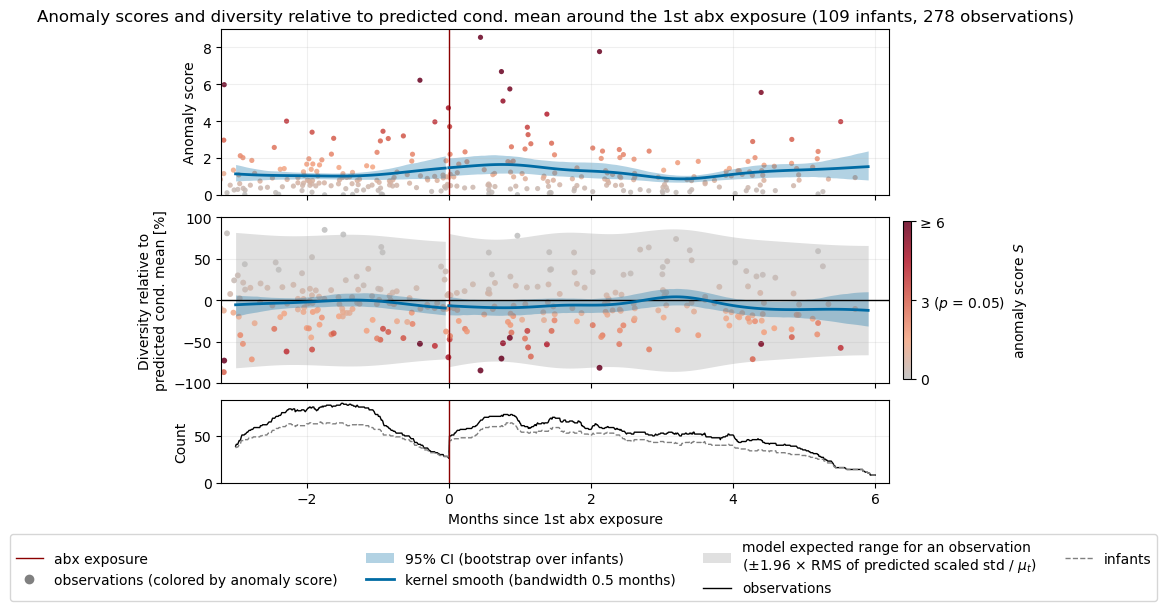

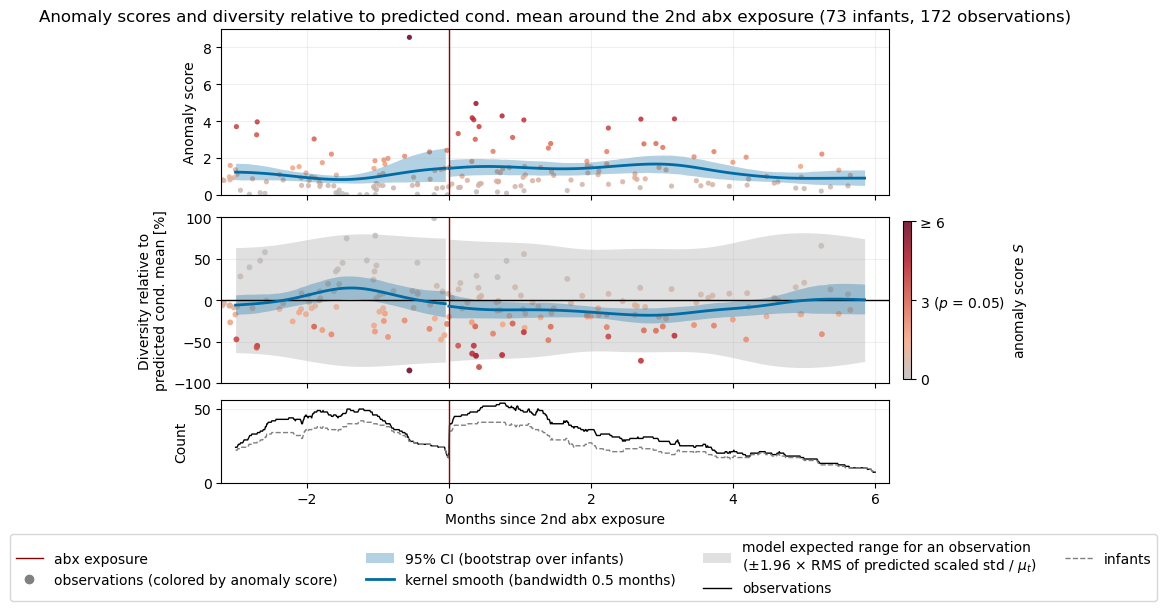

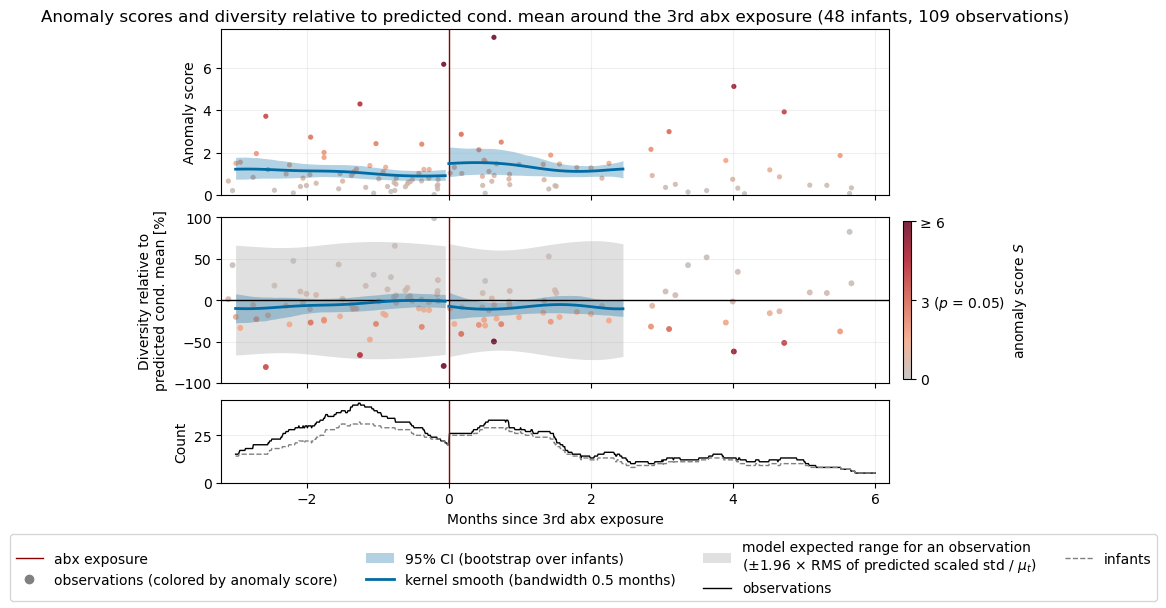

,exposure,infants,observations_before,observations_after,score_before_exposure,score_at_exposure,largest_score_first_3_months,score_at_months,share_score_above_3_after,deficit_before_exposure_pct,deficit_at_exposure_pct,largest_deficit_first_3_months_pct,deficit_at_months,months_ci_below_expectation,expected_range_pct_before_exposure,expected_range_pct_at_exposure,expected_range_pct_at_end,share_within_expected_range_after,curve_shown_from_months,curve_shown_until_months
0,1,109,112,166,1.46,1.48,1.65,0.75,0.08,-9.62,-6.78,-9.21,0.80,"[(4.25, 4.9)]",71.01,80.46,66.04,0.93,-3.0,5.90
1,2,73,69,103,1.45,1.44,1.68,2.90,0.12,-4.34,-7.29,-18.30,2.80,"[(0.45, 4.15)]",74.81,73.65,74.11,0.90,-3.0,5.85
2,3,48,52,57,0.91,1.48,1.53,0.40,0.07,-1.36,-7.37,-10.96,0.55,"[(0.4, 1.05)]",65.54,68.18,67.98,0.91,-3.0,2.45


In [8]:
score_threshold = -np.log(0.05)  # S = 3: left-tail p-value of 0.05
# color of an observation by its anomaly score: grey (S = 0) to dark red (S >= 6)
score_cmap = LinearSegmentedColormap.from_list(
    "anomaly", ["#bdbdbd", "#f4a582", "#d6604d", "#b2182b", "#67001f"]
)
score_norm = Normalize(vmin=0.0, vmax=6.0, clip=True)
summary = []
for n in [1, 2, 3]:
    if True:
        samples, curve = around_exposure[n], curves[n]
        sides = [curve[~curve["after_exposure"]], curve[curve["after_exposure"]]]
        suffix = _get_ordinal_suffix(n)
        # same figure size, font sizes and legend placement as the box-plot figures
        fig, (ax_s, ax, ax_n) = plt.subplots(
            3, 1, figsize=(9, 6), sharex=True,
            gridspec_kw={"height_ratios": [1, 1, 0.5]}, constrained_layout=True,
        )

        # panel 1: anomaly score over continuous time
        ax_s.axvline(0, color="darkred", linewidth=1, label="abx exposure")
        ax_s.scatter(samples["months_since_abx"], samples["score"], c=samples["score"],
                     cmap=score_cmap, norm=score_norm, s=14, alpha=0.85, linewidths=0)
        ax_s.plot([], [], marker="o", linestyle="None", color="grey",
                  label="observations (colored by anomaly score)")
        for i, side in enumerate(sides):
            ax_s.fill_between(
                side["months_since_abx"], side["score_ci_lower"], side["score_ci_upper"],
                color="C0", alpha=0.3, linewidth=0,
                label="95% CI (bootstrap over infants)" if i == 0 else None,
            )
            ax_s.plot(
                side["months_since_abx"], side["score_smoothed"], color="C0", linewidth=2,
                label=f"kernel smooth (bandwidth {bandwidth_months} months)" if i == 0 else None,
            )
        ax_s.set_ylim(0, 1.05 * samples["score"].max())
        ax_s.set_ylabel("Anomaly score", fontsize=10)
        ax_s.set_title(
            f"Anomaly scores and diversity relative to predicted cond. mean around the "
            f"{n}{suffix} abx exposure ({samples['host_id'].nunique()} infants, "
            f"{len(samples)} observations)",
            fontsize=12,
        )
        ax_s.grid(alpha=0.2)

        # panel 2: relative deficit with the model's expected range, dots colored by score
        for i, side in enumerate(sides):
            ax.fill_between(
                side["months_since_abx"], -side["expected_range_pct"], side["expected_range_pct"],
                color="lightgrey", alpha=0.7, linewidth=0,
                label=("model expected range for an observation\n"
                       "(±1.96 × RMS of predicted scaled std / $\\mu_t$)")
                if i == 0 else None,
            )
        ax.axvline(0, color="darkred", linewidth=1)
        ax.axhline(0, color="black", linewidth=1)
        points = ax.scatter(
            samples["months_since_abx"], samples["rel_deficit"], c=samples["score"],
            cmap=score_cmap, norm=score_norm, s=18, alpha=0.85, linewidths=0,
        )
        for side in sides:
            ax.fill_between(
                side["months_since_abx"], side["rel_deficit_ci_lower"],
                side["rel_deficit_ci_upper"], color="C0", alpha=0.3, linewidth=0,
            )
            ax.plot(side["months_since_abx"], side["rel_deficit_smoothed"], color="C0",
                    linewidth=2)
        limit = max(100.0, 1.1 * np.nanmax(curve["expected_range_pct"]))
        ax.set_ylim(-limit, limit)
        ax.set_ylabel("Diversity relative to\npredicted cond. mean [%]", fontsize=10)
        ax.grid(alpha=0.2)
        colorbar = fig.colorbar(points, ax=ax, pad=0.02, shrink=0.95, ticks=[0, 3, 6])
        colorbar.set_label("anomaly score $S$", fontsize=10)
        colorbar.ax.set_yticklabels(["0", "3 ($p$ = 0.05)", "≥ 6"])

        # panel 3: observations contributing to the displayed value at each time point
        # (within support_bandwidths bandwidths, on the same side of the exposure as the
        # smoothing) and the unique infants they come from
        grid_all = np.arange(min_samples, max_samples + 1e-9, 0.01)
        months_all = samples["months_since_abx"].to_numpy()
        hosts_all = samples["host_id"].to_numpy()
        after_all = samples["after_exposure"].to_numpy()
        reach = support_bandwidths * bandwidth_months
        contributes = (np.abs(months_all[None, :] - grid_all[:, None]) <= reach)
        contributes &= after_all[None, :] == (grid_all[:, None] >= 0)
        ax_n.plot(grid_all, contributes.sum(axis=1), color="black", linewidth=1,
                  label="observations")
        ax_n.plot(grid_all, [len(np.unique(hosts_all[c])) for c in contributes], color="grey",
                  linewidth=1, linestyle="--", label="infants")
        ax_n.axvline(0, color="darkred", linewidth=1)
        ax_n.set_ylim(bottom=0)
        ax_n.set_ylabel("Count", fontsize=10)
        ax_n.set_xlabel(f"Months since {n}{suffix} abx exposure", fontsize=10)
        ax_n.set_xlim(min_samples - 0.2, max_samples + 0.2)
        ax_n.grid(alpha=0.2)

        handles, labels = [], []
        for axis in (ax_s, ax, ax_n):
            for handle, label in zip(*axis.get_legend_handles_labels()):
                if label not in labels:
                    handles.append(handle)
                    labels.append(label)
        fig.legend(handles, labels, loc="outside lower center", ncol=4)
        stem = f"{evaluation_path}rel_deficit_after_{n}_abx"
        for ext in ["pdf", "png"]:
            fig.savefig(f"{stem}.{ext}", dpi=400, bbox_inches="tight")
        plt.show()
        curve.to_csv(f"{stem}_curve.csv", index=False)

        # smoothed values just before and at the exposure, extremes within the first 3
        # months after it, stretches of time over which the 95% CI of the relative deficit
        # lies below the expectation, the model's expected range, and how many observations
        # exceed score 3
        # a side without enough infants has no curve: its entries become NaN
        def value_at(curve_side, col, position):
            return curve_side[col].iloc[position] if len(curve_side) else np.nan

        before = sides[0].dropna(subset=["rel_deficit_smoothed"])
        shown = sides[1].dropna(subset=["rel_deficit_smoothed"])
        early = shown[shown["months_since_abx"] <= 3.0]
        i_min = early["rel_deficit_smoothed"].idxmin() if len(early) else None
        i_max_score = early["score_smoothed"].idxmax() if len(early) else None
        below = (shown["rel_deficit_ci_upper"] < 0).to_numpy()
        edges = np.flatnonzero(np.diff(np.concatenate(([False], below, [False]))))
        months = shown["months_since_abx"].to_numpy()
        below_stretches = [
            (round(months[start], 2), round(months[end - 1], 2))
            for start, end in zip(edges[::2], edges[1::2])
        ]
        after = samples[samples["after_exposure"]]
        summary.append(
            {
                "exposure": n,
                "infants": samples["host_id"].nunique(),
                "observations_before": int((~samples["after_exposure"]).sum()),
                "observations_after": int(samples["after_exposure"].sum()),
                "score_before_exposure": value_at(before, "score_smoothed", -1),
                "score_at_exposure": value_at(shown, "score_smoothed", 0),
                "largest_score_first_3_months": (
                    early.loc[i_max_score, "score_smoothed"] if len(early) else np.nan),
                "score_at_months": (
                    early.loc[i_max_score, "months_since_abx"] if len(early) else np.nan),
                "share_score_above_3_after": (after["score"] > score_threshold).mean(),
                "deficit_before_exposure_pct": value_at(before, "rel_deficit_smoothed", -1),
                "deficit_at_exposure_pct": value_at(shown, "rel_deficit_smoothed", 0),
                "largest_deficit_first_3_months_pct": (
                    early.loc[i_min, "rel_deficit_smoothed"] if len(early) else np.nan),
                "deficit_at_months": (
                    early.loc[i_min, "months_since_abx"] if len(early) else np.nan),
                "months_ci_below_expectation": below_stretches,
                "expected_range_pct_before_exposure": value_at(before, "expected_range_pct", -1),
                "expected_range_pct_at_exposure": value_at(shown, "expected_range_pct", 0),
                "expected_range_pct_at_end": value_at(shown, "expected_range_pct", -1),
                "share_within_expected_range_after": (after["z"].abs() <= 1.96).mean(),
                "curve_shown_from_months": value_at(before, "months_since_abx", 0),
                "curve_shown_until_months": value_at(shown, "months_since_abx", -1),
            }
        )
summary_df = pd.DataFrame(summary).round(2)
summary_df.to_csv(f"{evaluation_path}rel_deficit_summary.csv", index=False)
summary_df

## Relative deficit per month

Samples are selected with `_select_samples_around_nth_abx_exposure` from `evaluate_scores.ipynb` with the same settings as the score box plots there (`group_samples=True`): one sample per infant and month, and the samples before the exposure grouped into the last one within `min_samples` months before it, labelled -1. The score box plots themselves are produced by `evaluate_scores.ipynb` and are not repeated. The figure below follows the drawing conventions of those score box plots (`_create_subplot`): box plots per month, the sample counts below with the numbers of samples entering the unpaired and paired tests outlined, and stars for the one-sided tests against the -1 reference (Mann-Whitney U unpaired in orange, Wilcoxon paired in green; `**` p < 0.05, `*` p < 0.1), here for a decrease of the relative deficit. The three exposures share the x-axis and one legend. The grey line marks the model expectation.

In [9]:
binned = {}
for n in [1, 2, 3]:
    df = _select_samples_around_nth_abx_exposure(
        cond_moments[n], abx_df, n=n, min_samples=min_samples, max_samples=max_samples,
        group_samples=True, score_var="score", max_resolution=False,
    ).copy()
    df["diff_age_nth_abx"] = df["diff_age_nth_abx"].astype(float)
    df["neg_rel_deficit"] = -df["rel_deficit"]  # tests for a decrease of the deficit
    binned[n] = df
pd.DataFrame({n: df.groupby("diff_age_nth_abx").size() for n, df in binned.items()}).T

diff_age_nth_abx,-1.0,0.0,1.0,2.0,3.0,4.0,5.0
1,74,37,33,30,22,26,14
2,51,32,18,16,13,8,10
3,34,22,10,4,7,7,5


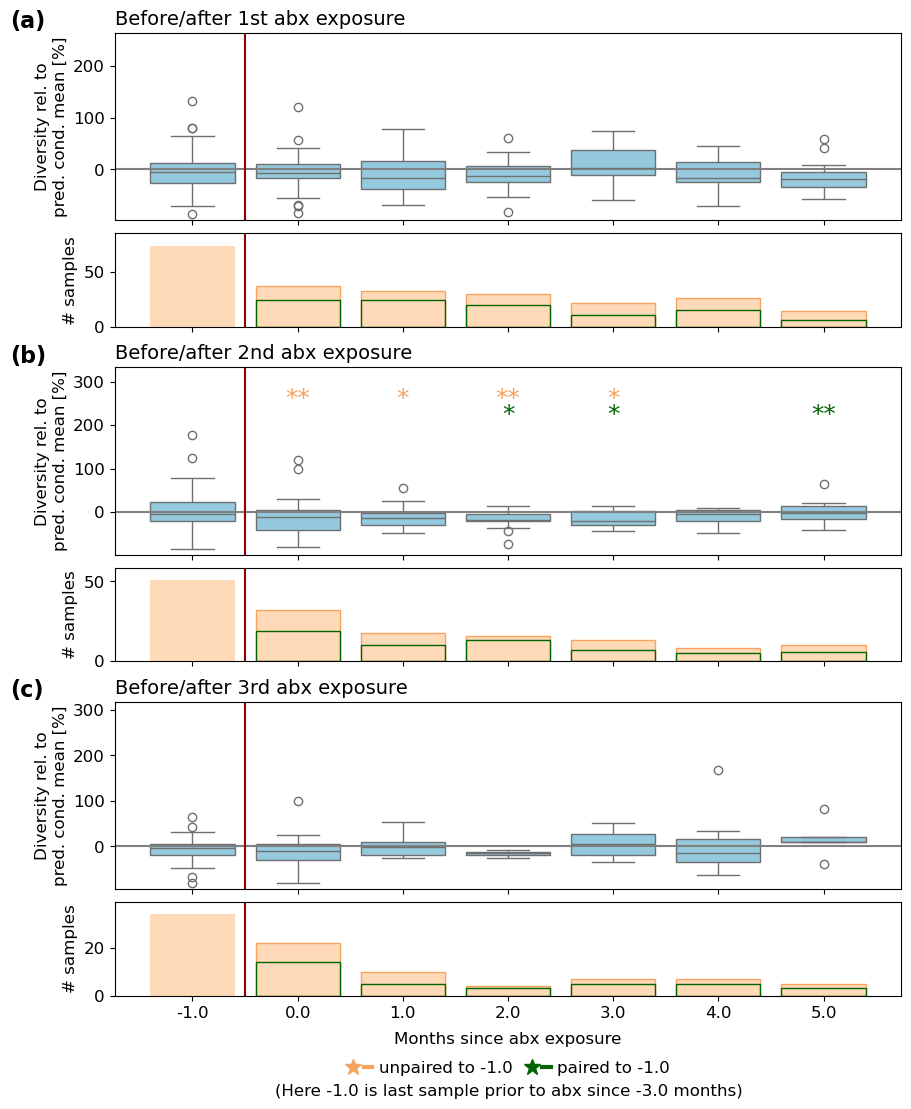

p_unpaired               p_paired               n_paired            
exposure          1      2      3        1      2      3        1     2     3
month                                                                        
0.0           0.612  0.042  0.261    0.228  0.508  0.108     24.0  19.0  14.0
1.0           0.157  0.051  0.695    0.506  0.246  0.312     24.0  10.0   5.0
2.0           0.271  0.025  0.138    0.139  0.055  0.125     20.0  13.0   3.0
3.0           0.925  0.051  0.798    0.995  0.078  0.406     11.0   7.0   5.0
4.0           0.216  0.226  0.400    0.619  0.688  0.906     15.0   5.0   5.0
5.0           0.118  0.473  0.936    0.500  0.047  0.750      6.0   6.0   3.0

In [10]:
bin_levels = [-1.0] + list(np.arange(0.0, max_samples, 1.0))
positions = np.arange(len(bin_levels))
zero_index = bin_levels.index(0.0)
# colors as in _create_subplot of evaluate_scores.ipynb; the star rows sit above the
# box plot range of each panel (offsets in units of that range)
test_style = {"unpaired": ("sandybrown", 0.26), "paired": ("darkgreen", 0.12)}

font_rc = {"font.size": boxplot_font_size, "axes.titlesize": boxplot_font_size,
           "axes.labelsize": boxplot_font_size - 2, "xtick.labelsize": boxplot_font_size - 2,
           "ytick.labelsize": boxplot_font_size - 2, "legend.fontsize": boxplot_font_size - 4}
significance_rows = []

with plt.rc_context(font_rc):
    fig, axes = plt.subplots(
        6, 1, figsize=(9, 11), sharex=True,
        gridspec_kw={"height_ratios": [1, 0.5] * 3}, constrained_layout=True,
    )
    # the panels leave a strip at the bottom for the legend and the footnote
    fig.get_layout_engine().set(rect=(0, 0.05, 1, 0.95))
    for i, n in enumerate([1, 2, 3]):
        ax_box, ax_count = axes[2 * i], axes[2 * i + 1]
        df = binned[n].copy()
        df["bin"] = pd.Categorical(df["diff_age_nth_abx"], categories=bin_levels)
        suffix = _get_ordinal_suffix(n)
        # one-sided tests against the -1 reference for a decrease of the relative deficit
        tests = perform_significance_tests(
            df, -1.0, list(np.arange(-1.0, max_samples, 1.0)), "neg_rel_deficit"
        )

        sns.boxplot(x="bin", y="rel_deficit", data=df, ax=ax_box, color="skyblue")
        ax_box.axhline(0, color="grey")
        # y-range of this panel: all of its values plus headroom above for the two star
        # rows and a free margin below the top of the panel
        y_low, y_high = df["rel_deficit"].min(), df["rel_deficit"].max()
        y_range = y_high - y_low
        ax_box.set_ylim(y_low - 0.05 * y_range, y_high + 0.6 * y_range)
        for test, (color, y_shift) in test_style.items():
            for t1, p_value in zip(tests.index, tests[f"P-value {test}"]):
                if p_value < 0.1:
                    ax_box.text(bin_levels.index(t1), y_high + y_shift * y_range,
                                "**" if p_value < 0.05 else "*", color=color, ha="center",
                                fontsize=18)
        ax_box.set_title(f"Before/after {n}{suffix} abx exposure", loc="left")
        # panel letter at the left edge of the figure, level with the panel's top
        ax_box.text(0.005, 1.0, f"({'abc'[i]})", fontsize=boxplot_font_size + 2,
                    fontweight="bold", va="bottom", ha="left",
                    transform=transforms.blended_transform_factory(fig.transFigure, ax_box.transAxes))
        ax_box.set_ylabel("Diversity rel. to\npred. cond. mean [%]", fontsize=boxplot_font_size - 2)
        ax_box.set_xlabel("")

        counts = df.groupby("bin", observed=False).size().to_numpy()
        ax_count.bar(positions, counts, width=0.8, color="peachpuff")
        for test, (color, _) in test_style.items():
            ax_count.bar([bin_levels.index(t1) for t1 in tests.index],
                         tests[f"# samples {test}"].to_numpy(), width=0.8,
                         facecolor="none", edgecolor=color)
        ax_count.set_ylim(0, 1.15 * counts.max())
        ax_count.set_ylabel("# samples", fontsize=boxplot_font_size - 2)
        ax_count.set_xlabel("")
        for axis in (ax_box, ax_count):
            axis.axvline(zero_index - 0.5, color="darkred")

        for t1 in tests.index:
            significance_rows.append(
                {"exposure": n, "month": t1,
                 "p_unpaired": tests.loc[t1, "P-value unpaired"],
                 "n_unpaired": tests.loc[t1, "# samples unpaired"],
                 "p_paired": tests.loc[t1, "P-value paired"],
                 "n_paired": tests.loc[t1, "# samples paired"]}
            )

    axes[-1].set_xticks(positions, [f"{level:.1f}" for level in bin_levels])
    axes[-1].set_xlabel("Months since abx exposure", labelpad=8)
    # one legend of the stars (box panels) and outlines (count panels) for all
    # panels, centred under them right above the footnote
    fig.draw_without_rendering()
    centre = (axes[-1].get_position().x0 + axes[-1].get_position().x1) / 2
    legend_above_footnote(
        fig, centre, f"(Here -1.0 is last sample prior to abx since {min_samples} months)",
        fontsize=boxplot_font_size - 2, markersize=12, linewidth=3,
    )
    for ext in ["pdf", "png"]:
        fig.savefig(f"{evaluation_path}rel_deficit_boxplots.{ext}", dpi=400, bbox_inches="tight")
    plt.show()

significance_df = pd.DataFrame(significance_rows).round(3)
significance_df.to_csv(f"{evaluation_path}boxplot_significance.csv", index=False)
significance_df.pivot(index="month", columns="exposure", values=["p_unpaired", "p_paired", "n_paired"])